# Lecture 6: Density Operators, Open-System Dynamics, and Entanglement

[Course contents](../00_course_contents.md) | [← Previous lecture](./05_quantum_dynamics_and_measurement.ipynb) | [Next lecture →](./07_bloch_sphere_and_quantum_gates.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

## Learning objectives

- Test whether a matrix is a physical density operator and compute expectation values and purity.
- Model relaxation and dephasing with quantum channels and a Lindblad master equation.
- Obtain subsystem states with the partial trace.
- Use Schmidt coefficients and reduced-state entropy to characterize bipartite pure-state entanglement.
- Distinguish entanglement correlations from communication.

## Core ideas

- **Density operators unify pure states, mixtures, and reduced states.** Positivity and unit trace are non-negotiable physical constraints.
- **Open-system evolution is a quantum channel.** Relaxation and dephasing affect populations and coherences differently.
- **Entanglement is nonseparability, not a signaling channel.** Reduced states and Schmidt coefficients make the distinction precise.


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
from sympy.physics.quantum import *
from sympy.physics.quantum.qubit import Qubit
from sympy.physics.quantum.dagger import Dagger
from sympy.physics.quantum.qapply import qapply
from sympy.physics.quantum.represent import represent
from sympy.physics.quantum import pauli
from IPython.core.interactiveshell import InteractiveShell
from sympy.physics.quantum import TensorProduct
import math
import numpy as np
import matplotlib.pyplot as plt
import sympy as sy
import scipy as sp

## Recorded lecture

[Watch "Density matrices and entanglement" on YouTube](https://www.youtube.com/watch?v=6mUvTuOUvB8).


In [2]:
# Import general libraries

%matplotlib inline

In [3]:
#Activate multiple output
InteractiveShell.ast_node_interactivity = "all"

## Density operators: pure states, mixtures, and reduced states


A normalized vector $\lvert\psi\rangle$ describes a pure state. Its density operator is

$$\rho_\psi=\lvert\psi\rangle\langle\psi\rvert.$$

A preparation that selects normalized states $\lvert\psi_i\rangle$ with classical probabilities $p_i$ is described by

$$\rho=\sum_i p_i\lvert\psi_i\rangle\langle\psi_i\rvert,
\qquad p_i\ge 0,\qquad \sum_i p_i=1.$$

The same formalism describes a subsystem entangled with degrees of freedom that are ignored. These situations are operationally identical if they give the same $\rho$: no measurement on the subsystem alone can reveal which ensemble decomposition was used.

Ensemble decompositions are not unique. For example,

$$\frac{I}{2}=\frac12\bigl(\lvert0\rangle\langle0\rvert+\lvert1\rangle\langle1\rvert\bigr)
=\frac12\bigl(\lvert+\rangle\langle+\rvert+\lvert-\rangle\langle-\rvert\bigr).$$


### Expectation values and measurement probabilities

For an observable $A$,

$$\langle A\rangle=\sum_i p_i\langle\psi_i\rvert A\lvert\psi_i\rangle
=\operatorname{Tr}(\rho A).$$

The equality follows from cyclicity of the trace:

$$\operatorname{Tr}\!\left(\lvert\psi_i\rangle\langle\psi_i\rvert A\right)
=\langle\psi_i\rvert A\lvert\psi_i\rangle.$$

For a POVM with effects $E_m\succeq0$ and $\sum_mE_m=I$,

$$p(m)=\operatorname{Tr}(\rho E_m).$$

Thus $\rho$ contains exactly the information required to predict every measurement on the system, but it does not specify a unique preparation history.


### Which matrices are physical states?

A finite-dimensional density operator satisfies

$$\boxed{\rho=\rho^\dagger,\qquad \rho\succeq0,\qquad \operatorname{Tr}\rho=1}.$$

Positivity means $\langle v\rvert\rho\lvert v\rangle\ge0$ for every $\lvert v\rangle$, so all eigenvalues are nonnegative. Together with unit trace, this makes them a probability distribution.

The purity is

$$\gamma=\operatorname{Tr}(\rho^2).$$

In dimension $d$,

$$\frac1d\le\gamma\le1.$$

The upper bound is reached exactly by pure states, equivalently $\rho^2=\rho$ and $\operatorname{rank}\rho=1$. The lower bound is reached by the maximally mixed state $I/d$. Purity alone does not identify a mixed state. For a qubit, trace and purity determine the unordered eigenvalues but not the eigenbasis; in dimensions $d\ge3$, even different spectra can share the same purity.


### Example: a pure qubit

For

$$\lvert\psi\rangle=c_0\lvert0\rangle+c_1\lvert1\rangle,
\qquad \lvert c_0\rvert^2+\lvert c_1\rvert^2=1,$$

the outer product is

$$\boxed{\rho_\psi=
\begin{bmatrix}
\lvert c_0\rvert^2 & c_0c_1^*\\
c_1c_0^* & \lvert c_1\rvert^2
\end{bmatrix}}.$$

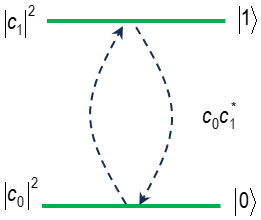

The diagonal entries are computational-basis probabilities. The off-diagonal entries are coherences relative to that basis; a basis change redistributes which entries are diagonal. The phase of $c_0c_1^*$ affects interference, while a global phase of $\lvert\psi\rangle$ cancels from $\rho_\psi$.


## Quantum channels and Kraus operators

A deterministic physical evolution of a density operator is modeled by a completely positive trace-preserving (CPTP) map. In Kraus form,

$$\mathcal E(\rho)=\sum_k K_k\rho K_k^\dagger,
\qquad \sum_kK_k^\dagger K_k=I.$$

The second relation preserves trace. Complete positivity is stronger than ordinary positivity: $\mathcal E\otimes\mathcal I$ must map every joint state to a positive operator, even when the system is entangled with an untouched reference.

Amplitude damping with probability $\gamma$ uses

$$K_0=\begin{bmatrix}1&0\\0&\sqrt{1-\gamma}\end{bmatrix},
\qquad K_1=\begin{bmatrix}0&\sqrt\gamma\\0&0\end{bmatrix}.$$

It maps $\rho_{11}\mapsto(1-\gamma)\rho_{11}$ and $\rho_{01}\mapsto\sqrt{1-\gamma}\rho_{01}$. By contrast, the phase-flip channel

$$\mathcal E_Z(\rho)=(1-p)\rho+pZ\rho Z$$

leaves populations unchanged and multiplies off-diagonal entries by $1-2p$. Kraus representations are not unique, even though the channel is.


## Markovian relaxation and dephasing

A common continuous-time model is the Gorini-Kossakowski-Sudarshan-Lindblad equation,

$$\frac{d\rho}{dt}=-\frac{i}{\hbar}[H,\rho]
+\sum_j\Gamma_j\left(L_j\rho L_j^\dagger-
\frac12\{L_j^\dagger L_j,\rho\}\right).$$

For exponential relaxation toward an equilibrium excited-state population $\rho_{11}^{\mathrm{eq}}$ and independent pure dephasing,

$$\rho_{11}(t)=\rho_{11}^{\mathrm{eq}}+
\bigl[\rho_{11}(0)-\rho_{11}^{\mathrm{eq}}\bigr]e^{-t/T_1},\qquad
\rho_{01}(t)=e^{-t/T_2}\rho_{01}(0).$$

The familiar zero-temperature amplitude-damping expression follows when $\rho_{11}^{\mathrm{eq}}=0$. With

$$\boxed{\frac1{T_2}=\frac1{2T_1}+\frac1{T_\phi}},$$

one obtains $T_2\le2T_1$ in this model. $T_2^*$ usually denotes an inhomogeneous Ramsey decay time and can be shorter than an echo-derived $T_2$. These parameters summarize particular experiments and models; non-Markovian or nonexponential behavior requires a more detailed description.

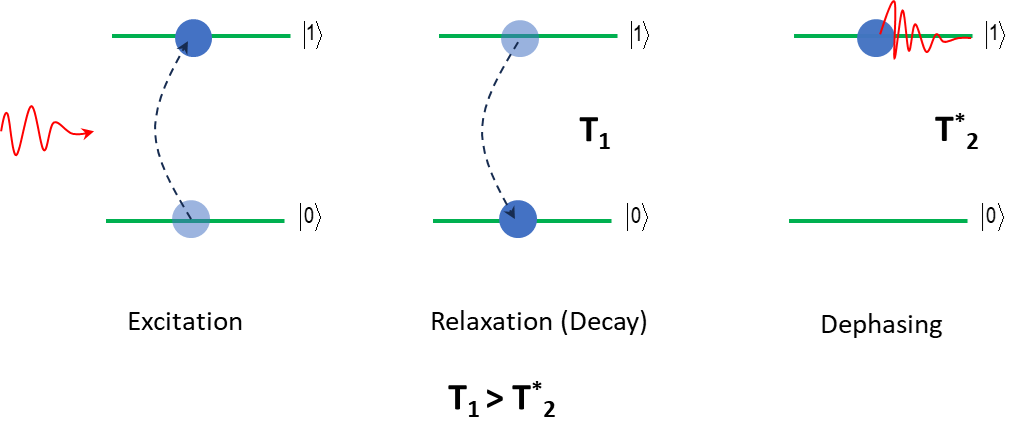

Primary reference: G. Lindblad, ["On the Generators of Quantum Dynamical Semigroups"](https://doi.org/10.1007/BF01608499), *Communications in Mathematical Physics* 48, 119-130 (1976).


## Composite systems and tensor products


If systems $A$ and $B$ have Hilbert spaces $\mathcal H_A$ and $\mathcal H_B$, their joint space is $\mathcal H_A\otimes\mathcal H_B$, with dimension $d_Ad_B$. Independently prepared pure states have product form $\lvert\psi_A\rangle\otimes\lvert\psi_B\rangle$, but a general joint state need not factor.

For two qubits, using basis order $\lvert00\rangle,\lvert01\rangle,\lvert10\rangle,\lvert11\rangle$,

$$\lvert00\rangle=\begin{bmatrix}1\\0\\0\\0\end{bmatrix},\quad
\lvert01\rangle=\begin{bmatrix}0\\1\\0\\0\end{bmatrix},\quad
\lvert10\rangle=\begin{bmatrix}0\\0\\1\\0\end{bmatrix},\quad
\lvert11\rangle=\begin{bmatrix}0\\0\\0\\1\end{bmatrix}.$$

Basis-vector ordering is a software convention and must be checked when moving between libraries.


### Partial trace: the state of a subsystem

For a joint density operator $\rho_{AB}$, subsystem $A$ is described by

$$\rho_A=\operatorname{Tr}_B(\rho_{AB})
=\sum_j (I_A\otimes\langle j\rvert)\rho_{AB}(I_A\otimes\lvert j\rangle),$$

where $\{\lvert j\rangle\}$ is any orthonormal basis of $B$. It is characterized by

$$\operatorname{Tr}(\rho_A A)=\operatorname{Tr}\!\left[\rho_{AB}(A\otimes I_B)\right]$$

for every observable $A$ on the first subsystem.

For $\lvert\Phi^+\rangle=(\lvert00\rangle+\lvert11\rangle)/\sqrt2$,

$$\rho_A=\rho_B=\frac{I}{2}.$$

The joint state is pure, but each qubit alone is maximally mixed. Local mixedness can therefore arise from entanglement, not only from classical uncertainty or uncontrolled noise.


In [4]:
# SymPy Quantum
Qubit('0')
Qubit('1')

|0>

|1>

In [5]:
# SymPy Quantum
represent(Qubit('0'))
represent(Qubit('1'))

Matrix([
[1],
[0]])

Matrix([
[0],
[1]])

In [6]:
TensorProduct(Qubit('0'), Qubit('1'))
represent(TensorProduct(Qubit('0'), Qubit('1')))

|0>x|1>

Matrix([
[0],
[1],
[0],
[0]])

In [7]:
# Multi-qubit computational-basis states in SymPy
represent(Qubit('00'))
represent(Qubit('01'))
represent(Qubit('10'))
represent(Qubit('11'))

Matrix([
[1],
[0],
[0],
[0]])

Matrix([
[0],
[1],
[0],
[0]])

Matrix([
[0],
[0],
[1],
[0]])

Matrix([
[0],
[0],
[0],
[1]])

For normalized single-qubit states

$$\lvert\psi_A\rangle=\begin{bmatrix}a\\b\end{bmatrix},\qquad
\lvert\psi_B\rangle=\begin{bmatrix}c\\d\end{bmatrix},$$

their product is

$$\lvert\psi_A\rangle\otimes\lvert\psi_B\rangle
=\begin{bmatrix}ac\\ad\\bc\\bd\end{bmatrix}
=ac\lvert00\rangle+ad\lvert01\rangle+bc\lvert10\rangle+bd\lvert11\rangle.$$

A general $n$-qubit pure state requires $2^n$ complex amplitudes,

$$\lvert\psi\rangle=\sum_{x\in\{0,1\}^n}c_x\lvert x\rangle,
\qquad \sum_x\lvert c_x\rvert^2=1,$$

but most such states are not product states. The exponential amplitude count is a simulation cost, not by itself an algorithmic speedup: a measurement cannot reveal all amplitudes in one shot.


## Separability and the Schmidt decomposition

A bipartite pure state is separable exactly when it is a product. Every bipartite pure state has a Schmidt decomposition

$$\boxed{\lvert\psi\rangle_{AB}=\sum_{k=1}^{r}\sqrt{\lambda_k}
\lvert u_k\rangle_A\lvert v_k\rangle_B},$$

where $\lambda_k>0$, $\sum_k\lambda_k=1$, and the two sets of vectors are orthonormal. The state is entangled exactly when the Schmidt rank $r>1$. The nonzero eigenvalues of $\rho_A$ and $\rho_B$ are both $\{\lambda_k\}$.

For pure bipartite states, the entanglement entropy is

$$S(\rho_A)=S(\rho_B)=-\sum_k\lambda_k\log_2\lambda_k.$$

For example, $\lvert\Phi^+\rangle$ has Schmidt coefficients $1/\sqrt2,1/\sqrt2$ and one ebit of entanglement. A normalized separable comparison is

$$\frac{\lvert01\rangle+\lvert11\rangle}{\sqrt2}
=\lvert+\rangle\otimes\lvert1\rangle.$$

For mixed states, "separable" means a convex mixture of product states,

$$\rho_{AB}=\sum_i p_i\rho_A^{(i)}\otimes\rho_B^{(i)},$$

so a separable mixed state need not itself be one product operator.

### Computing Schmidt decompositions with an SVD

Choose product bases and arrange the amplitudes into a coefficient matrix $C$:

$$\lvert\psi\rangle=\sum_{i,j}C_{ij}\lvert i\rangle_A\lvert j\rangle_B.$$

The singular-value decomposition

$$C=U\Sigma V^\dagger$$

constructs the Schmidt decomposition. The nonzero singular values $s_k=\Sigma_{kk}$ are the Schmidt coefficients, the squared values $\lambda_k=s_k^2$ are the nonzero eigenvalues of both reduced density operators, and the number of singular values above a stated numerical tolerance is the Schmidt rank. The left and right singular-vector bases supply the subsystem Schmidt vectors, with complex conjugation determined by the coefficient-matrix convention. Before reshaping a state vector into $C$, state the basis and qubit order explicitly.


## Bell states, correlations, and no signaling

The four Bell states are

$$\lvert\Phi^\pm\rangle=\frac{\lvert00\rangle\pm\lvert11\rangle}{\sqrt2},
\qquad
\lvert\Psi^\pm\rangle=\frac{\lvert01\rangle\pm\lvert10\rangle}{\sqrt2}.$$

They are maximally entangled two-qubit states. For $\lvert\Phi^+\rangle$,

$$\langle X\otimes X\rangle=1,\qquad
\langle Y\otimes Y\rangle=-1,\qquad
\langle Z\otimes Z\rangle=1.$$

With $A_0=Z$, $A_1=X$, $B_0=(Z+X)/\sqrt2$, and $B_1=(Z-X)/\sqrt2$, the CHSH combination reaches

$$\langle A_0B_0\rangle+\langle A_0B_1\rangle+
\langle A_1B_0\rangle-\langle A_1B_1\rangle=2\sqrt2,$$

exceeding the local-hidden-variable bound $2$. Nevertheless, each local reduced state is $I/2$. Changing or measuring one qubit cannot alter the other party's unconditional outcome distribution, so entanglement cannot transmit a controllable message faster than light.

Primary reference: J. S. Bell, ["On the Einstein Podolsky Rosen Paradox"](https://doi.org/10.1103/PhysicsPhysiqueFizika.1.195), *Physics Physique Fizika* 1, 195-200 (1964).


## Tensor products of operators

If $A$ is $d_A\times d_A$ and $B$ is $d_B\times d_B$, then $A\otimes B$ is a $(d_Ad_B)\times(d_Ad_B)$ operator. For a $2\times2$ matrix $A$,

$$A\otimes B=\begin{bmatrix}
A_{00}B&A_{01}B\\
A_{10}B&A_{11}B
\end{bmatrix}.$$

An operation on $A$ alone is represented by $A\otimes I_B$ under the displayed subsystem ordering. Operators on disjoint factors commute:

$$[A\otimes I_B,I_A\otimes B]=0.$$


## Exponential state space and what an algorithm can read

An $n$-qubit pure state has $2^n$ amplitudes, and an unrestricted density matrix has $4^n$ complex entries before Hermiticity and trace constraints are applied. This explains why brute-force classical simulation becomes expensive.

It does **not** mean a quantum computer exposes $2^n$ classical answers at once. A computational-basis measurement returns one $n$-bit string per shot. Quantum algorithms obtain an advantage only when gates organize amplitudes so that interference, structure, and repeated measurements reveal a useful global property with lower total cost.


In [8]:
for n in (10, 20, 30, 40, 50):
    gib = (2**n * 16) / 2**30  # complex128 statevector storage
    print(f"n={n:2d}: {2**n:>16,d} amplitudes, about {gib:,.1f} GiB")

n=10:            1,024 amplitudes, about 0.0 GiB
n=20:        1,048,576 amplitudes, about 0.0 GiB
n=30:    1,073,741,824 amplitudes, about 16.0 GiB
n=40: 1,099,511,627,776 amplitudes, about 16,384.0 GiB
n=50: 1,125,899,906,842,624 amplitudes, about 16,777,216.0 GiB


In [9]:
# Inspect the library's basis ordering rather than inferring it from a plot.
state_101 = Qubit('101')
represent(state_101)

Matrix([
[0],
[0],
[0],
[0],
[0],
[1],
[0],
[0]])

## Key takeaways

- A physical density operator is Hermitian, positive semidefinite, and trace one.
- CPTP maps and Lindblad equations model deterministic open-system evolution in their respective regimes.
- The partial trace gives the locally accessible state of a subsystem.
- For bipartite pure states, Schmidt rank and reduced-state entropy quantify entanglement, while no-signaling remains intact.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information* (Cambridge University Press, 2010), Sections 2.4-2.5 and Chapter 8.
2. J. Preskill, [Quantum Information, Chapter 2](https://www.preskill.caltech.edu/ph219/chap2_15.pdf).
3. H.-P. Breuer and F. Petruccione, *The Theory of Open Quantum Systems* (Oxford University Press, 2002).
4. G. Lindblad, ["On the Generators of Quantum Dynamical Semigroups"](https://doi.org/10.1007/BF01608499), *Communications in Mathematical Physics* 48, 119-130 (1976).
5. J. S. Bell, ["On the Einstein Podolsky Rosen Paradox"](https://doi.org/10.1103/PhysicsPhysiqueFizika.1.195), *Physics Physique Fizika* 1, 195-200 (1964).
6. QuTiP documentation, [Lindblad master-equation solver](https://qutip.readthedocs.io/en/stable/guide/dynamics/dynamics-master.html).
